# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Mobile Usage Habits Dataset](https://www.kaggle.com/datasets/abirambharathisa/mobile-usage-and-addiction-habits-2026)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('mobile_usage_habits_2026.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,respondent_id,age,gender,daily_screen_time_hours,unlocks_per_day,social_media_hours,sleep_hours,anxiety_score,addiction_score,addicted_flag
0,1,17,Male,5.6,76,3.4,6.2,16.0,38.0,1
1,2,53,Male,3.6,57,2.5,6.5,12.2,24.2,0
2,3,47,Female,2.9,23,1.6,8.6,7.8,22.0,0
3,4,35,Female,2.9,35,1.2,7.1,7.7,28.8,0
4,5,35,Male,5.1,64,2.5,7.5,9.3,32.5,0


## last Five row

In [4]:
df.tail()

,respondent_id,age,gender,daily_screen_time_hours,unlocks_per_day,social_media_hours,sleep_hours,anxiety_score,addiction_score,addicted_flag
2995,2996,45,Female,4.6,52,1.9,8.3,11.3,23.3,0
2996,2997,28,Female,4.1,58,2.6,7.1,13.2,27.4,0
2997,2998,31,Male,6.0,61,2.1,6.1,9.9,34.0,0
2998,2999,35,Male,2.8,42,1.0,6.7,9.6,23.6,0
2999,3000,47,Male,4.7,49,2.8,6.6,9.7,34.4,0


## Shape of our dataset

In [5]:
df.shape

(3000, 10)

## List out all columns

In [6]:
df.columns

Index(['respondent_id', 'age', 'gender', 'daily_screen_time_hours',
       'unlocks_per_day', 'social_media_hours', 'sleep_hours', 'anxiety_score',
       'addiction_score', 'addicted_flag'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

respondent_id                int64
age                          int64
gender                      object
daily_screen_time_hours    float64
unlocks_per_day              int64
social_media_hours         float64
sleep_hours                float64
anxiety_score              float64
addiction_score            float64
addicted_flag                int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   respondent_id            3000 non-null   int64  
 1   age                      3000 non-null   int64  
 2   gender                   3000 non-null   object 
 3   daily_screen_time_hours  3000 non-null   float64
 4   unlocks_per_day          3000 non-null   int64  
 5   social_media_hours       3000 non-null   float64
 6   sleep_hours              3000 non-null   float64
 7   anxiety_score            3000 non-null   float64
 8   addiction_score          3000 non-null   float64
 9   addicted_flag            3000 non-null   int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 234.5+ KB


## Check Null Value

In [9]:
df.isnull().sum()

respondent_id              0
age                        0
gender                     0
daily_screen_time_hours    0
unlocks_per_day            0
social_media_hours         0
sleep_hours                0
anxiety_score              0
addiction_score            0
addicted_flag              0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,respondent_id,age,daily_screen_time_hours,unlocks_per_day,social_media_hours,sleep_hours,anxiety_score,addiction_score,addicted_flag
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,38.549667,5.000967,59.755000,2.498333,6.607767,8.717167,30.861633,0.185000
std,866.169729,15.054714,1.866684,26.702933,1.131511,0.931944,3.613572,7.938870,0.388362
min,1.000000,13.000000,0.500000,5.000000,0.200000,3.400000,0.000000,10.000000,0.000000
25%,750.750000,25.000000,3.800000,41.750000,1.700000,6.000000,6.300000,25.300000,0.000000
50%,1500.500000,38.000000,5.000000,60.000000,2.400000,6.600000,8.600000,30.900000,0.000000
75%,2250.250000,52.000000,6.300000,77.000000,3.200000,7.200000,11.125000,36.000000,0.000000
max,3000.000000,64.000000,11.200000,144.000000,7.000000,9.400000,20.500000,58.300000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

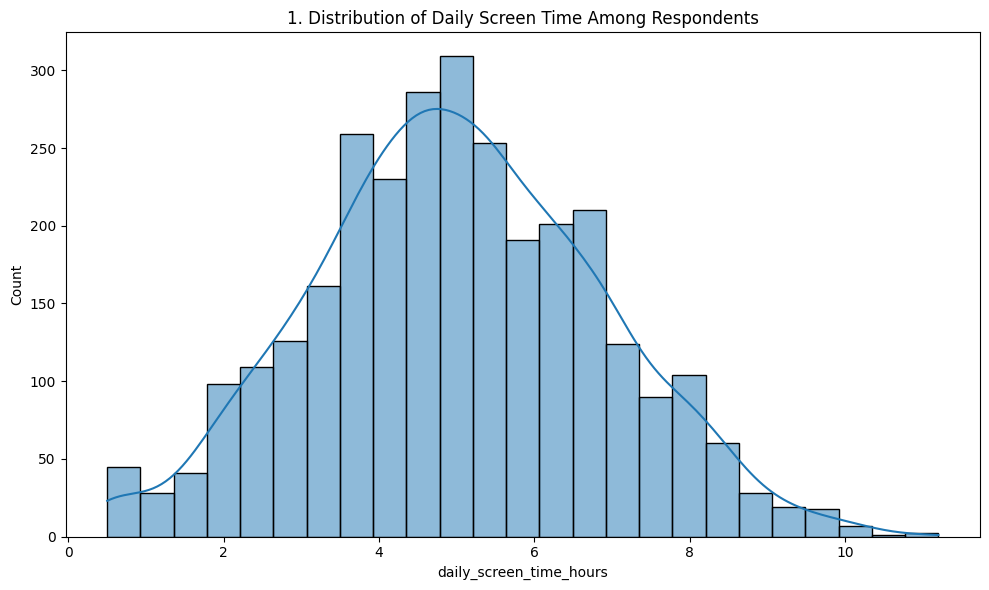

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='daily_screen_time_hours', kde=True, bins=25)
plt.title(f'{plot_no}. Distribution of Daily Screen Time Among Respondents')
show_fig()
plot_no += 1

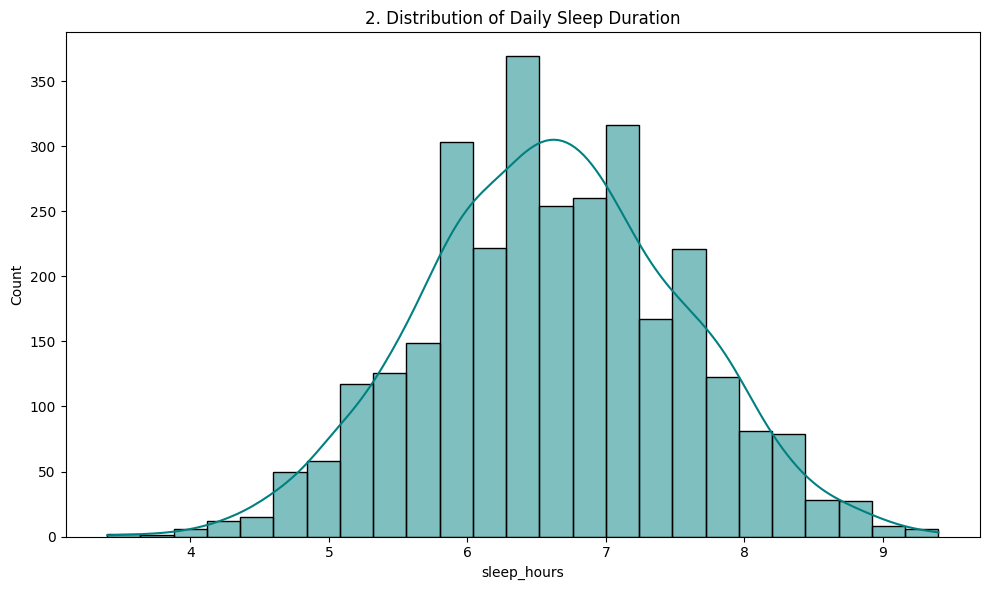

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='sleep_hours', kde=True, bins=25, color='teal')
plt.title(f'{plot_no}. Distribution of Daily Sleep Duration')
show_fig()
plot_no += 1

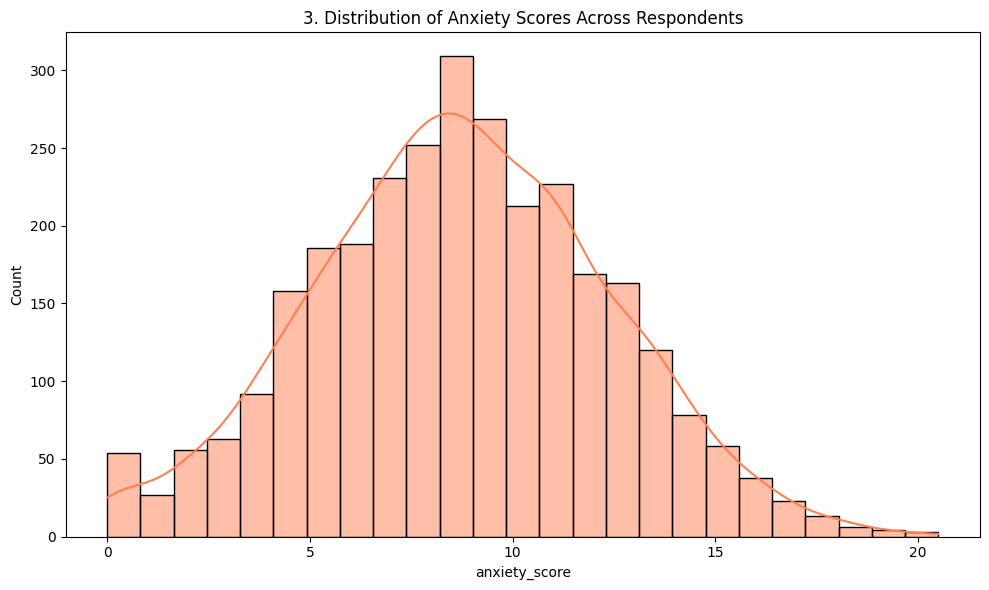

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='anxiety_score', kde=True, bins=25, color='coral')
plt.title(f'{plot_no}. Distribution of Anxiety Scores Across Respondents')
show_fig()
plot_no += 1

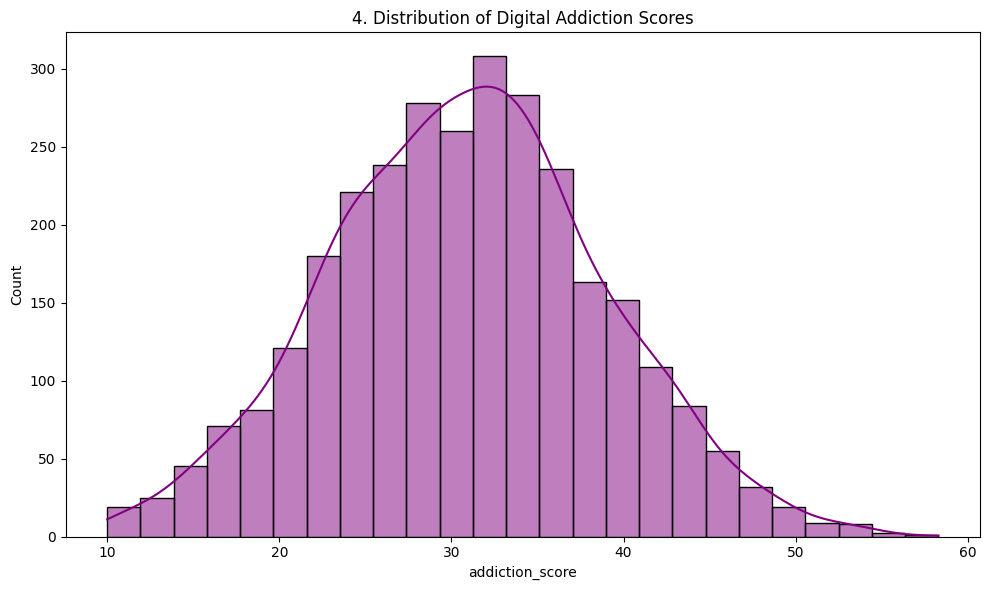

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='addiction_score', kde=True, bins=25, color='purple')
plt.title(f'{plot_no}. Distribution of Digital Addiction Scores')
show_fig()
plot_no += 1

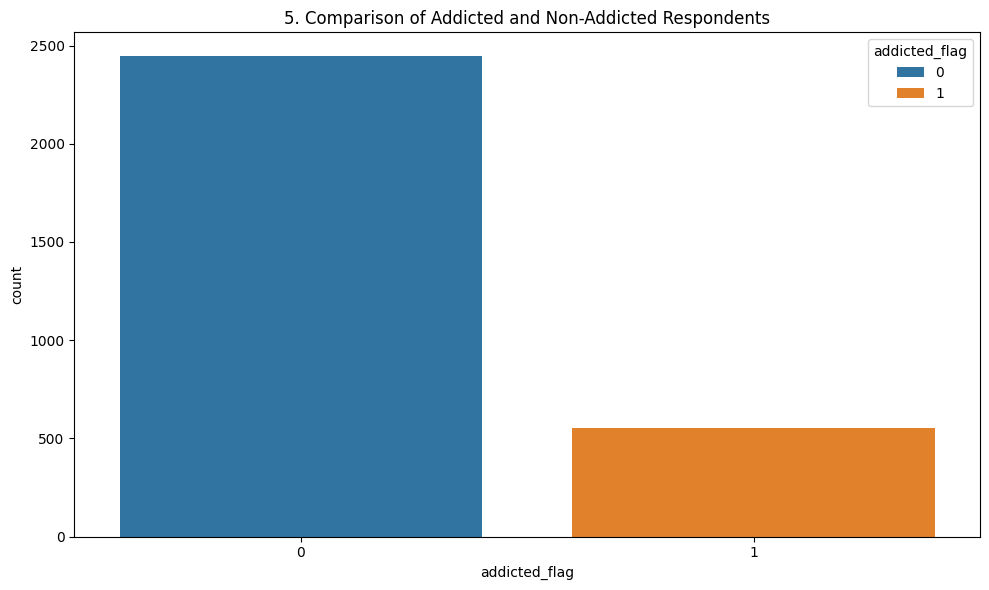

In [17]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='addicted_flag', hue='addicted_flag')
plt.title(f'{plot_no}. Comparison of Addicted and Non-Addicted Respondents')
show_fig()
plot_no += 1

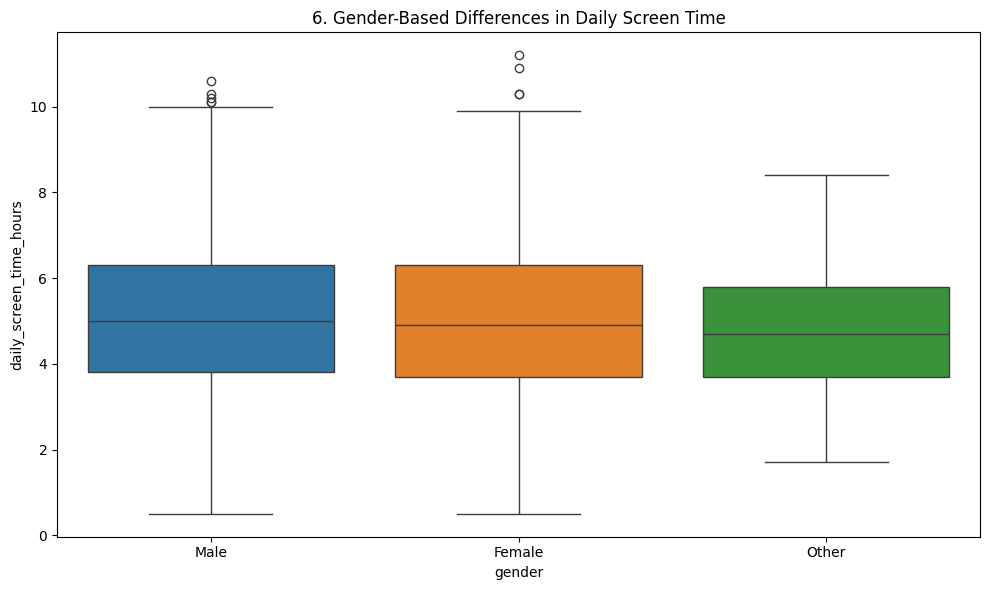

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='daily_screen_time_hours', hue='gender')
plt.title(f'{plot_no}. Gender-Based Differences in Daily Screen Time')
show_fig()
plot_no += 1

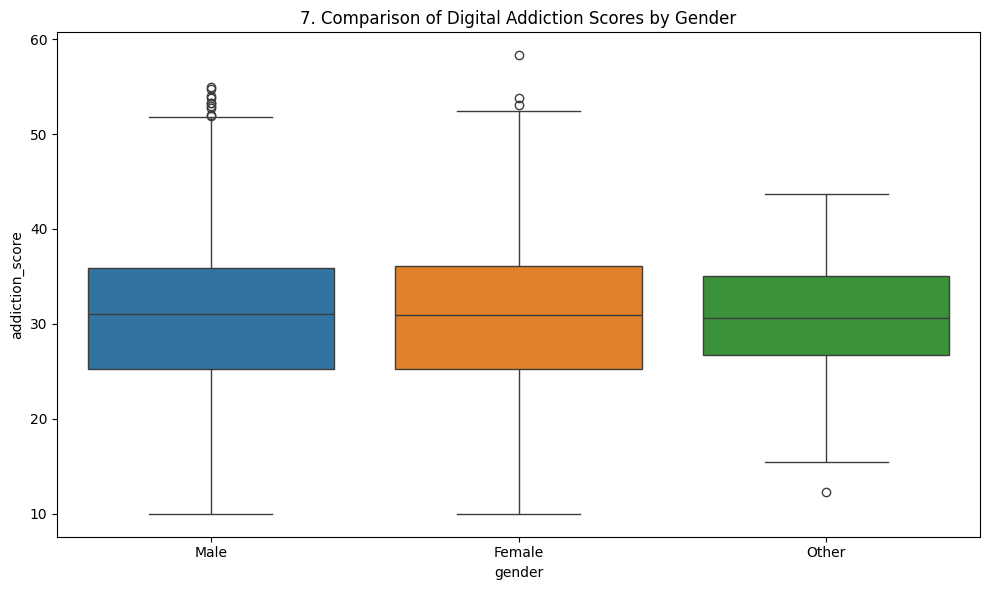

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='addiction_score', hue='gender')
plt.title(f'{plot_no}. Comparison of Digital Addiction Scores by Gender')
show_fig()
plot_no += 1

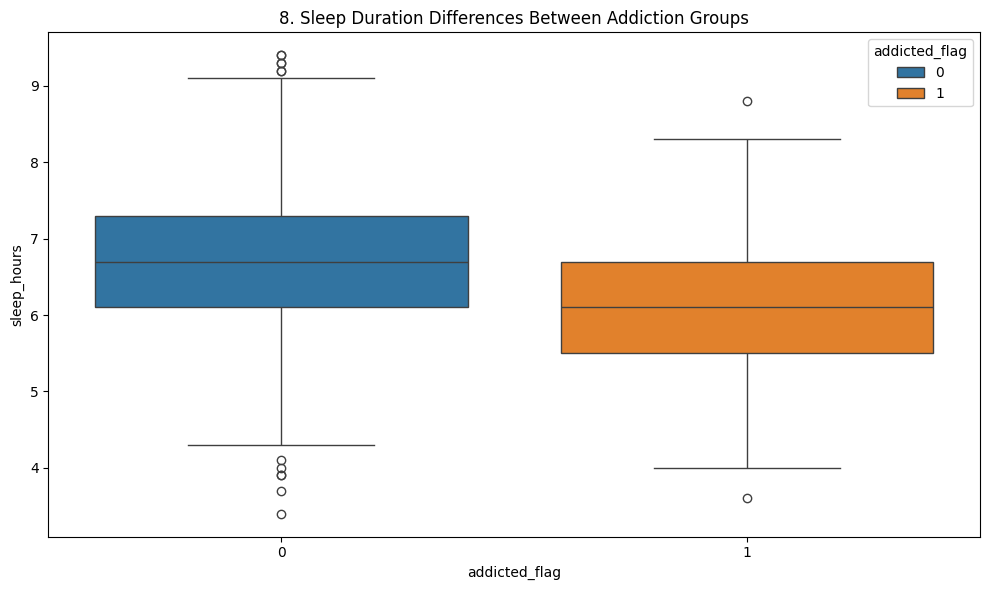

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='addicted_flag', y='sleep_hours', hue='addicted_flag')
plt.title(f'{plot_no}. Sleep Duration Differences Between Addiction Groups')
show_fig()
plot_no += 1

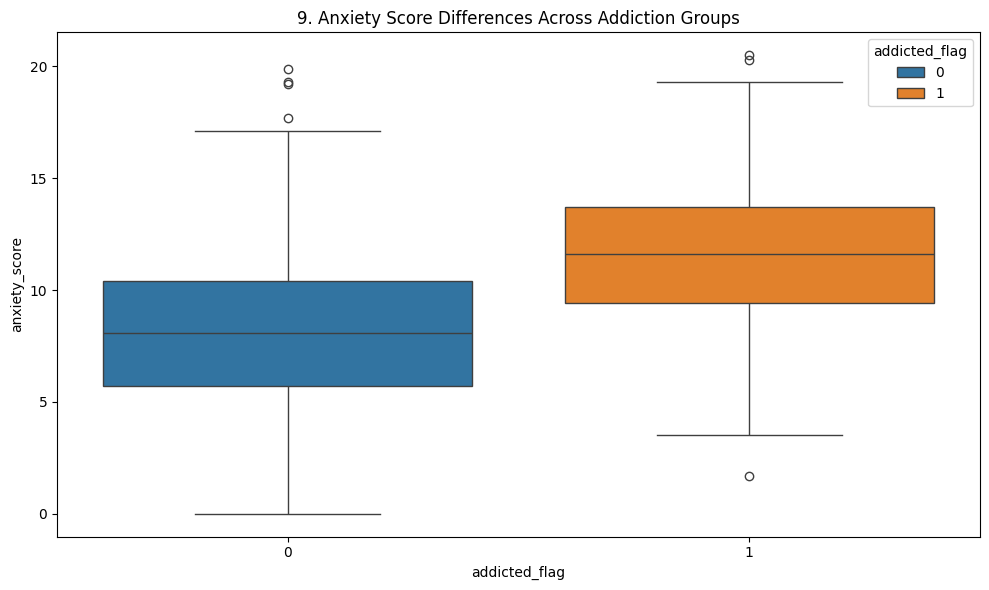

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='addicted_flag', y='anxiety_score', hue='addicted_flag')
plt.title(f'{plot_no}. Anxiety Score Differences Across Addiction Groups')
show_fig()
plot_no += 1

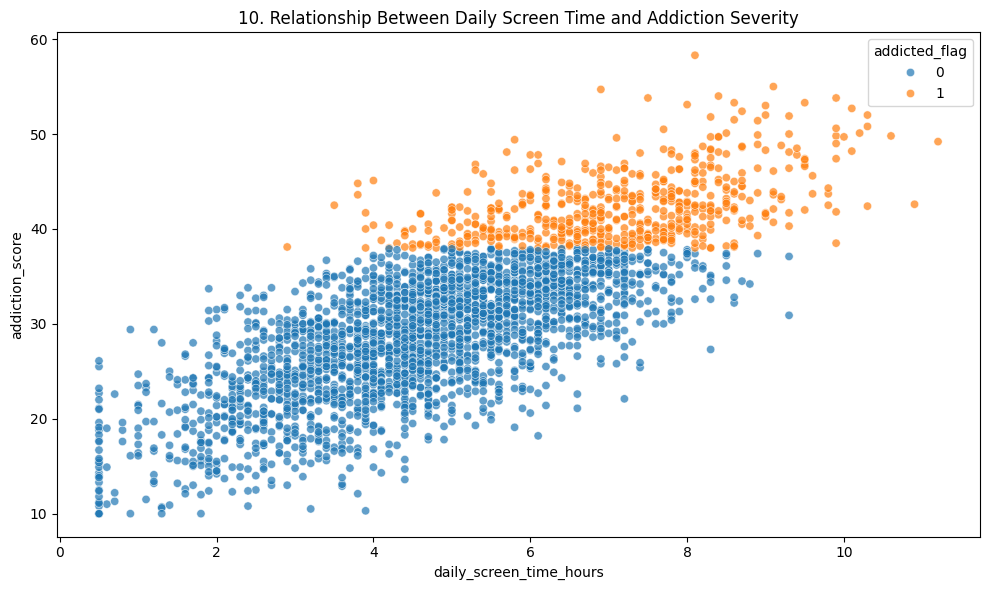

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='daily_screen_time_hours', y='addiction_score', hue='addicted_flag', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Daily Screen Time and Addiction Severity')
show_fig()
plot_no += 1

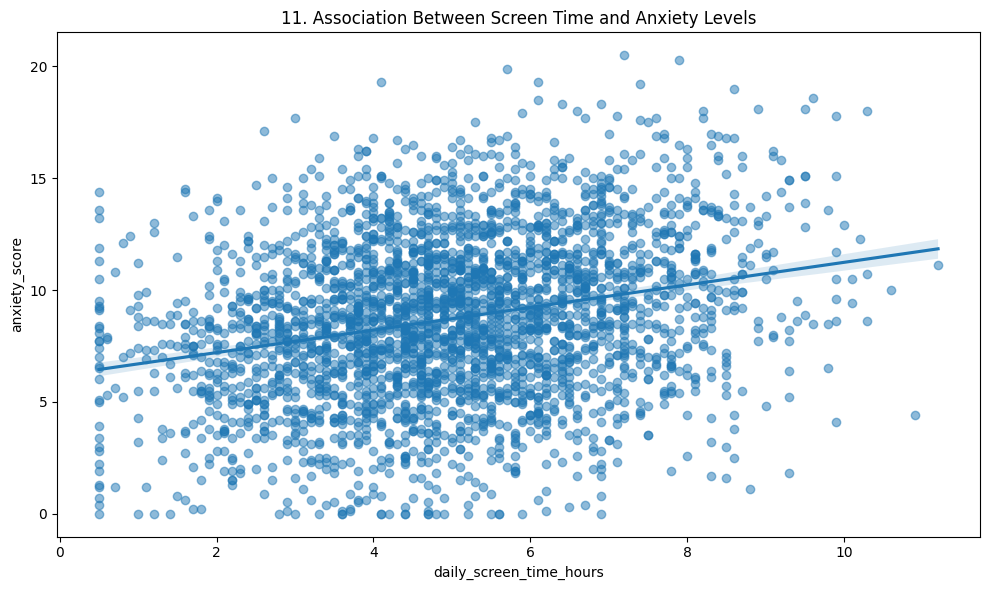

In [23]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='daily_screen_time_hours', y='anxiety_score', scatter_kws={'alpha':0.5})
plt.title(f'{plot_no}. Association Between Screen Time and Anxiety Levels')
show_fig()
plot_no += 1

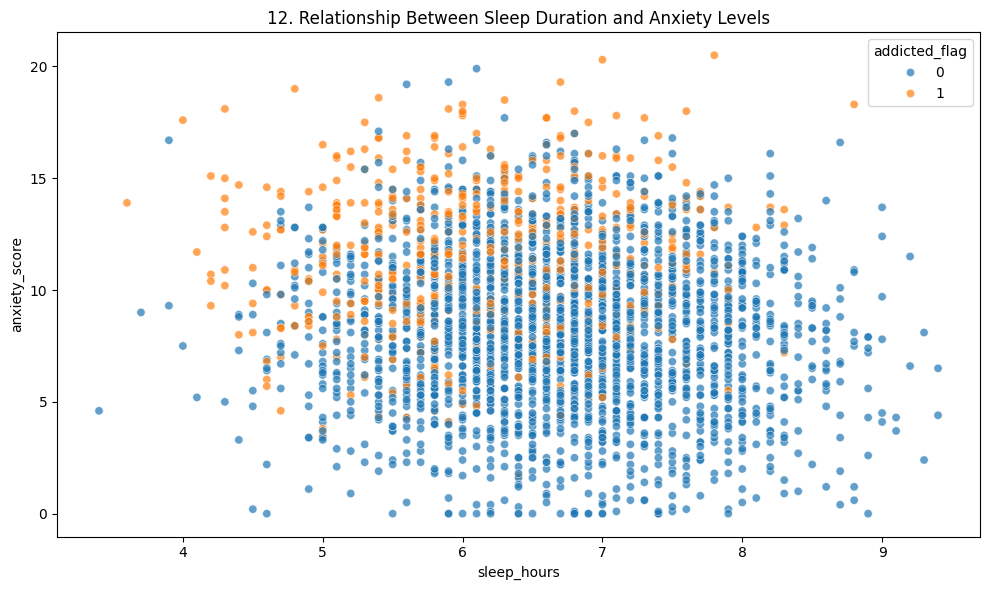

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='sleep_hours', y='anxiety_score', hue='addicted_flag', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Sleep Duration and Anxiety Levels')
show_fig()
plot_no += 1

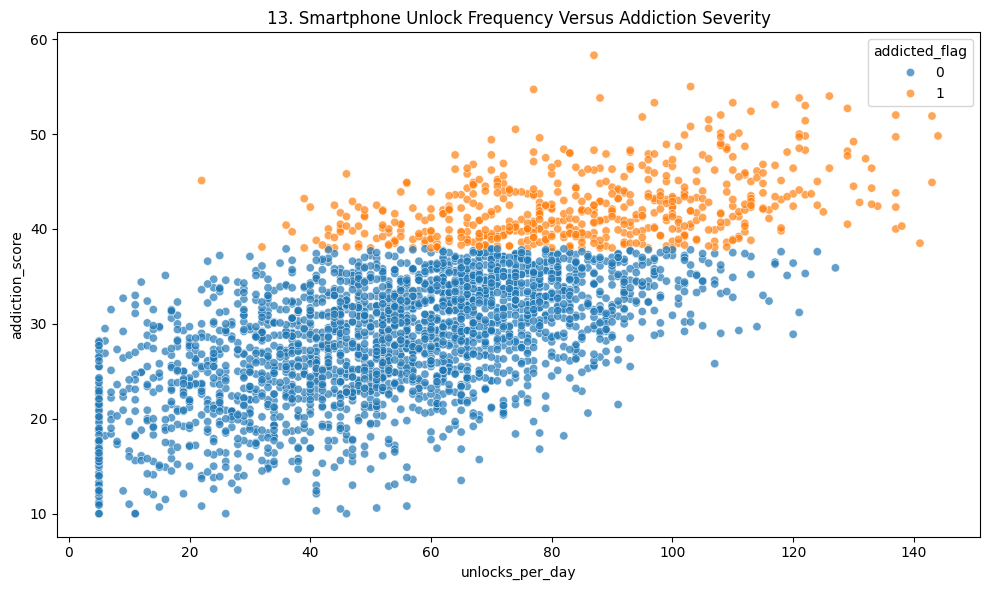

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='unlocks_per_day', y='addiction_score', hue='addicted_flag', alpha=0.7)
plt.title(f'{plot_no}. Smartphone Unlock Frequency Versus Addiction Severity')
show_fig()
plot_no += 1

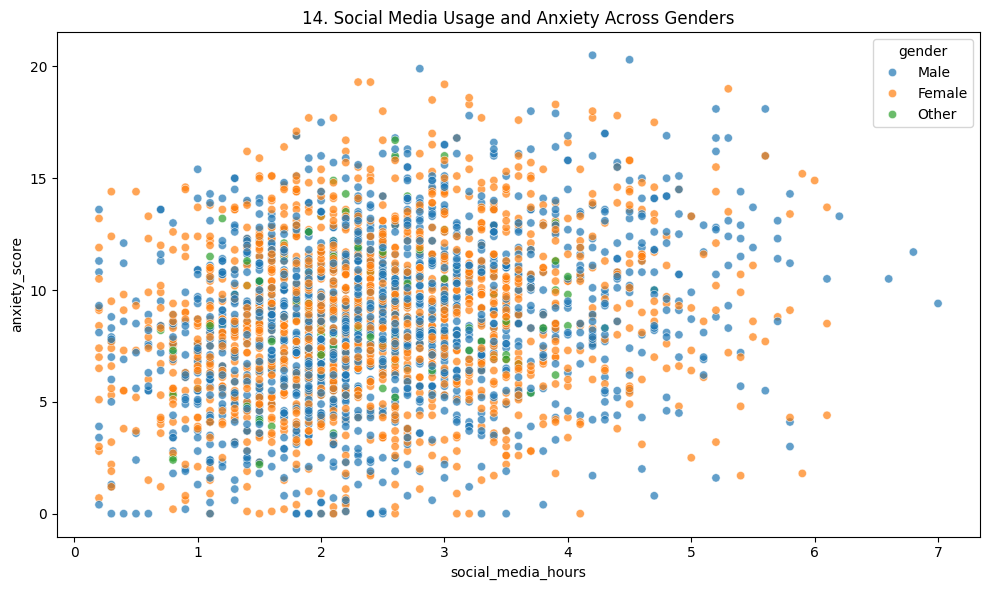

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_media_hours', y='anxiety_score', hue='gender', alpha=0.7)
plt.title(f'{plot_no}. Social Media Usage and Anxiety Across Genders')
show_fig()
plot_no += 1

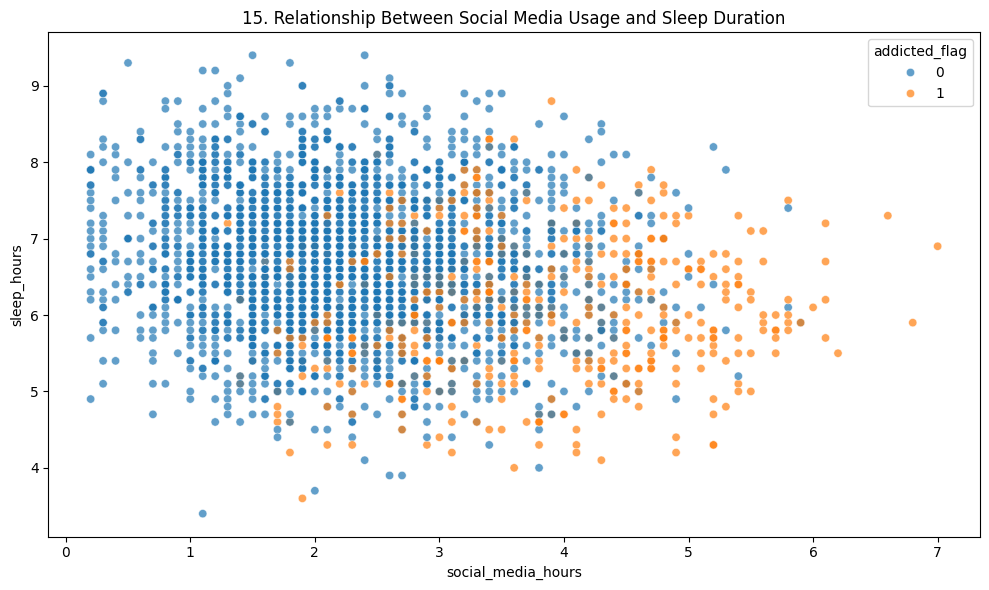

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_media_hours', y='sleep_hours', hue='addicted_flag', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Social Media Usage and Sleep Duration')
show_fig()
plot_no += 1

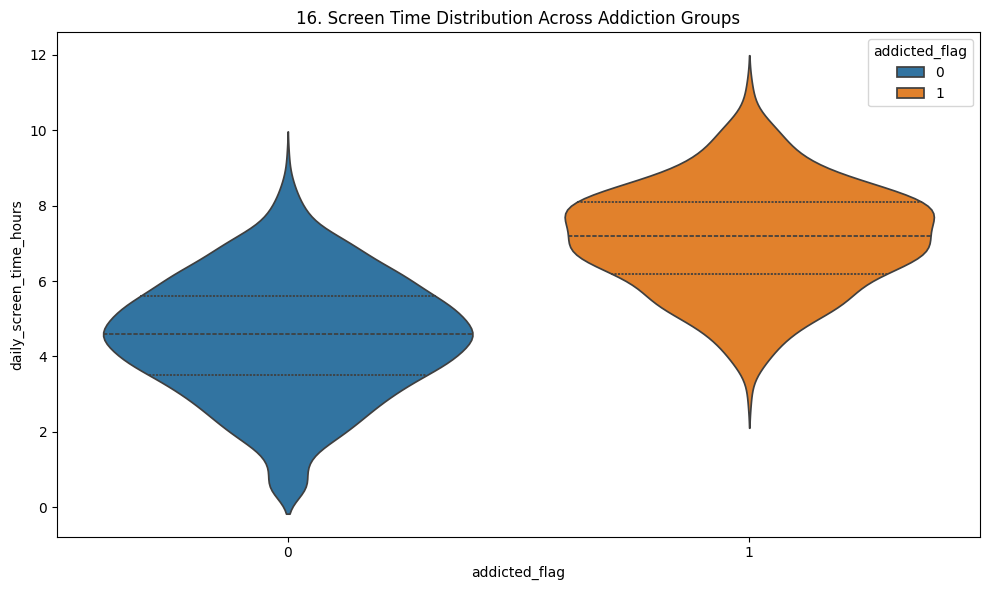

In [28]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='addicted_flag', y='daily_screen_time_hours', hue='addicted_flag', inner='quartile')
plt.title(f'{plot_no}. Screen Time Distribution Across Addiction Groups')
show_fig()
plot_no += 1

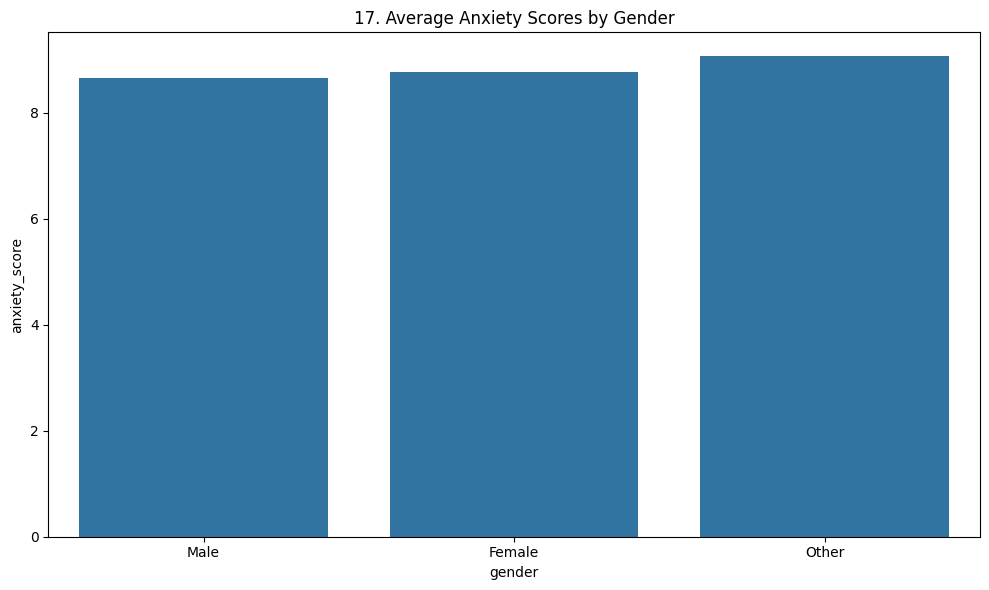

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='gender', y='anxiety_score', errorbar=None)
plt.title(f'{plot_no}. Average Anxiety Scores by Gender')
show_fig()
plot_no += 1

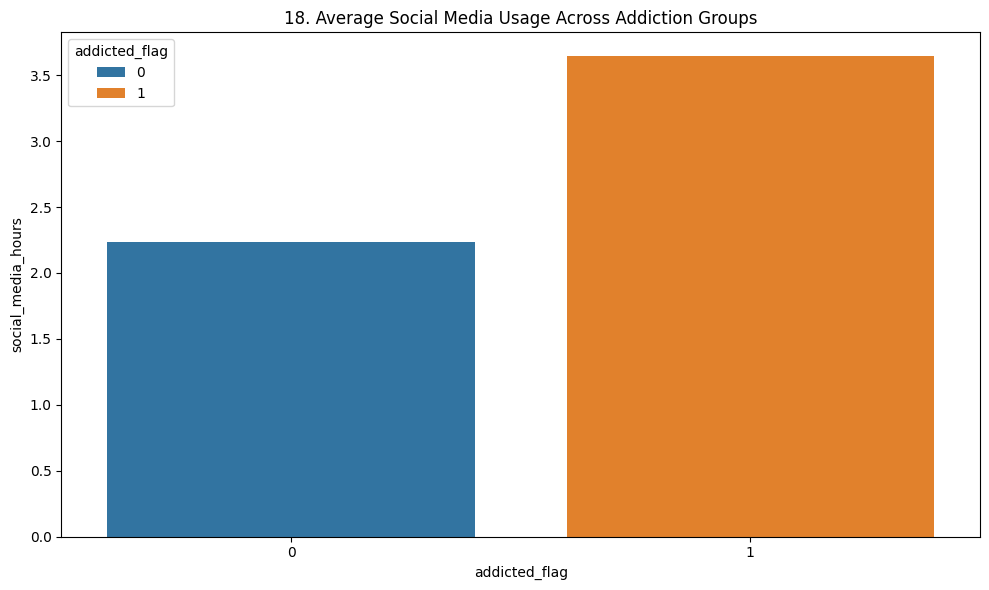

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='addicted_flag', y='social_media_hours', hue='addicted_flag', errorbar=None)
plt.title(f'{plot_no}. Average Social Media Usage Across Addiction Groups')
show_fig()
plot_no += 1

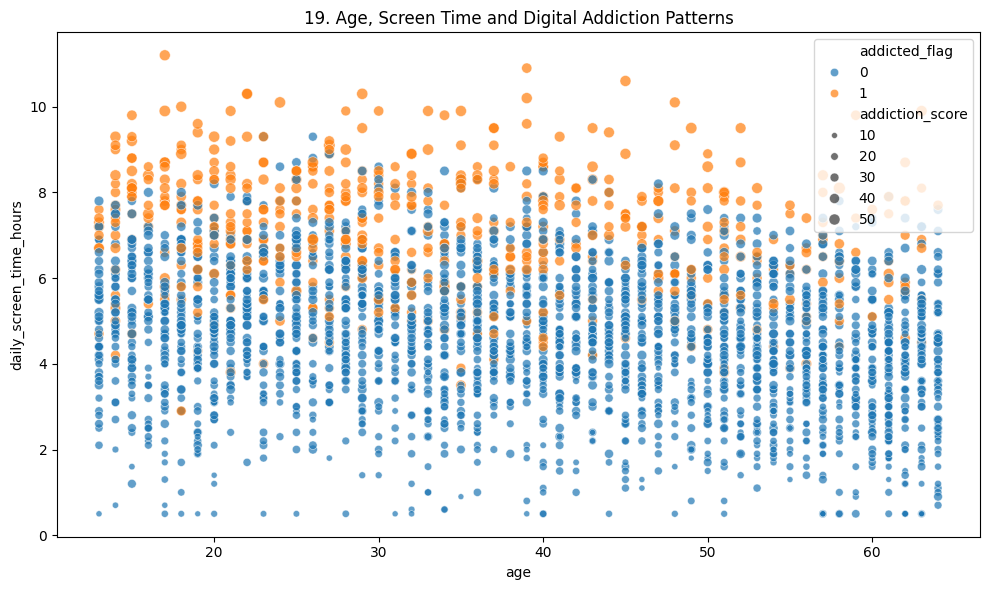

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='age', y='daily_screen_time_hours', hue='addicted_flag', size='addiction_score', alpha=0.7)
plt.title(f'{plot_no}. Age, Screen Time and Digital Addiction Patterns')
show_fig()
plot_no += 1

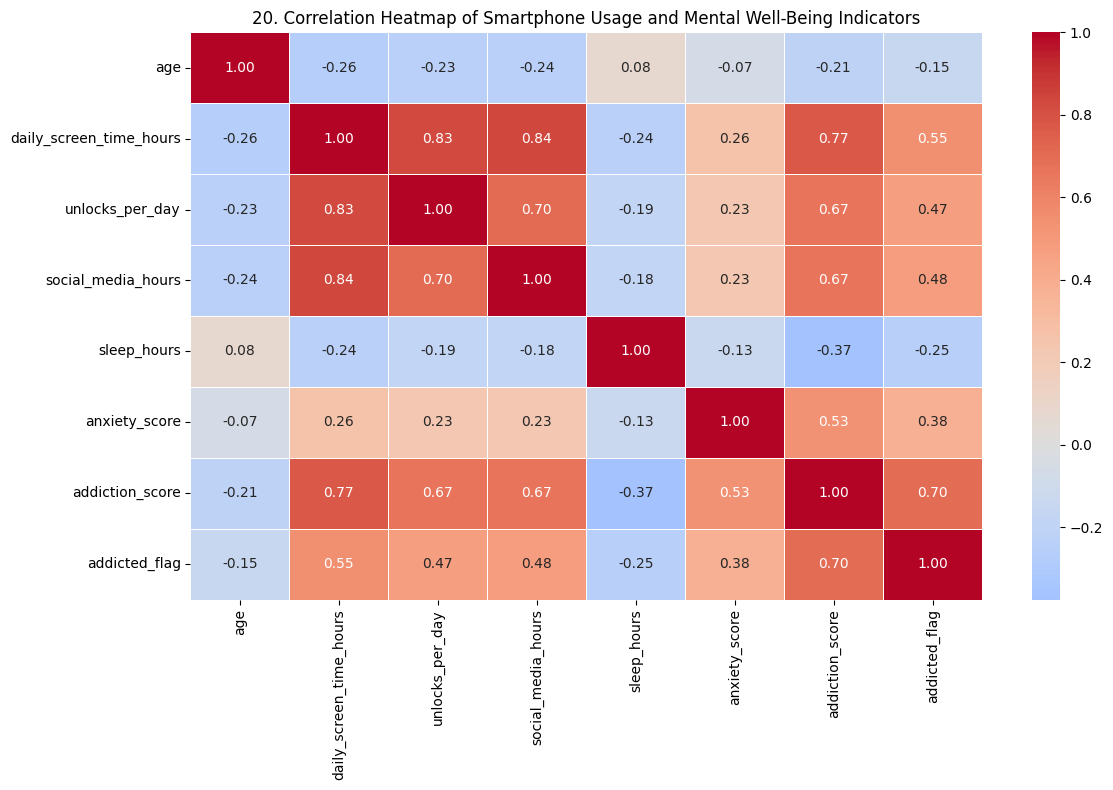

In [32]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').drop(columns=['respondent_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Smartphone Usage and Mental Well-Being Indicators')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [33]:
X = df.drop(columns=['respondent_id', 'addicted_flag', 'addiction_score'])
y = df['addicted_flag']

## Encode categorical variables

In [34]:
X = pd.get_dummies(X, drop_first=True)

## Split dataset into training and testing sets

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Build and train the model

In [36]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.9,
        random_state=42
    ))
])

model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,loss,'log_loss'
,learning_rate,0.05
,n_estimators,200
,subsample,0.9


## Generate predictions

In [37]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [38]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model Accuracy: 89.33 %

Classification Report:

              precision    recall  f1-score   support

           0       0.92      0.95      0.94       489
           1       0.75      0.63      0.69       111

    accuracy                           0.89       600
   macro avg       0.84      0.79      0.81       600
weighted avg       0.89      0.89      0.89       600



## Plot confusion matrix

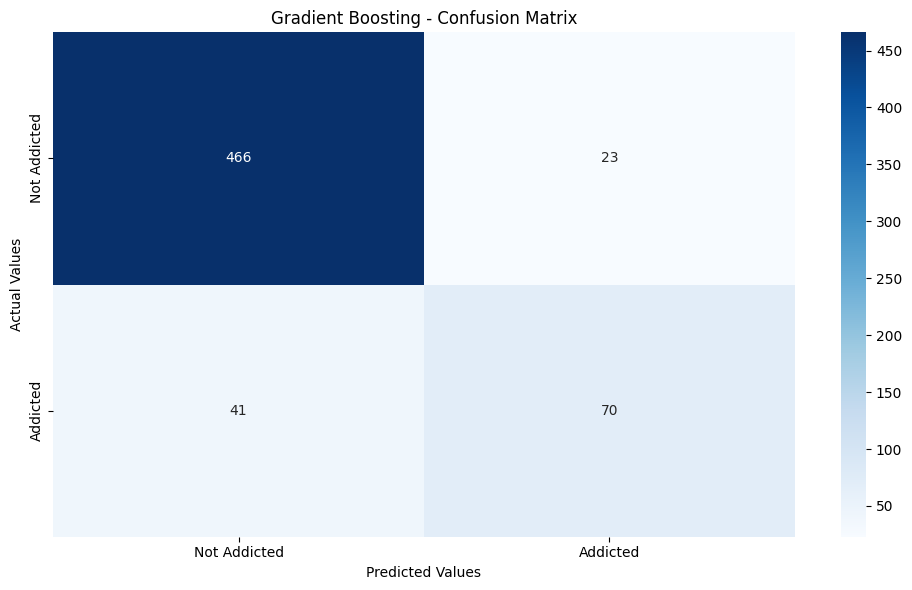

In [39]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Addicted', 'Addicted'],
            yticklabels=['Not Addicted', 'Addicted'])
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Gradient Boosting - Confusion Matrix')
show_fig()